# Knapsack

A software company is planning next quarter. Forty project proposals sit on the table, each with a
cost, a benefit score and a number of engineers it needs. The budget and the headcount cover only
part of the list. Some projects build on others, some are alternatives to each other, and two are
required by the auditors. The question is **which projects to fund, for the most benefit**.

This is a knapsack: each item is either in or out, and the items in must fit.

In this notebook you will:

1. describe the proposals and the rules as Python objects,
2. solve it and see the picked projects against the whole list,
3. check the result yourself, including an upper limit that no plan can beat,
4. turn a hard limit into a price, and see the plan buy past it,
5. change the budget and see where more money stops helping,
6. see why the search temperature must match the size of your values,
7. restart from last quarter's plan with projects pinned.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

from optimaru import knapsack as ks
from optimaru.knapsack import constraints as rules
from optimaru.knapsack.models import ItemModel, KnapsackProblemModel, SelectionGroupModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the proposals

Everything is a pydantic model, and `selected` on each item is what the solver fills in.

| Object | What it holds |
| --- | --- |
| `ItemModel` | one project: `id`, `weight` (here its cost), `value`, `resource_usage`, `requires` |
| `SelectionGroupModel` | a set of `item_ids` with `min_selected` and `max_selected` |
| `KnapsackProblemModel` | `capacity`, the `items`, `resource_capacities`, `mandatory_items`, `forbidden_items`, `selection_groups` |

`capacity` limits the total `weight`. `resource_capacities` adds as many other limits as you need,
one per name, and each item says how much it uses in `resource_usage`. `requires` lists items that
must also be picked when this one is.

Here is a fictional quarter. Costs are in thousands, benefit is an internal score, and each project
belongs to one of four themes.

In [2]:
THEMES = ["Platform", "Growth", "Compliance", "Cost saving"]
THEME_COLOR = dict(zip(THEMES, COLORS))
BUDGET, ENGINEERS = 1500, 26


def make_problem(budget=BUDGET, engineers=ENGINEERS):
    """A fresh, unsolved quarter. The solver works in place, so each experiment gets its own."""
    rng = np.random.default_rng(8)
    items = []
    for i in range(40):
        cost = int(rng.integers(40, 260))
        people = int(rng.integers(1, 7))
        benefit = int(max(2, cost / 12 * rng.uniform(0.5, 1.5) + people * rng.uniform(0, 2)))
        items.append(ItemModel(id=f"P{i:02d}", weight=cost, value=benefit, resource_usage={"engineers": people}))
    for i in range(4, 40, 3):  # later projects build on earlier ones
        items[i].requires = [items[int(rng.integers(0, i))].id]
    return KnapsackProblemModel(
        capacity=budget,
        items=items,
        resource_capacities={"engineers": engineers},
        mandatory_items=["P18", "P30"],
        forbidden_items=["P31"],
        selection_groups=[
            SelectionGroupModel(id="Billing rewrite", item_ids=["P01", "P13", "P25"], max_selected=1),
            SelectionGroupModel(id="Data centre move", item_ids=["P03", "P15", "P27", "P35"], max_selected=1),
            SelectionGroupModel(id="Security audit", item_ids=["P02", "P06", "P10"], max_selected=1),
        ],
    )


def theme_of(item_id):
    return THEMES[int(item_id[1:]) % len(THEMES)]


problem = make_problem()
print(f"{len(problem.items)} proposals asking for {sum(item.weight for item in problem.items)} "
      f"of a {problem.capacity} budget")
print(f"they need {sum(item.resource_usage['engineers'] for item in problem.items)} engineers, "
      f"{problem.resource_capacities['engineers']} are available")
print("auditors require:", problem.mandatory_items, " ruled out:", problem.forbidden_items)
print("dependencies    :", {item.id: item.requires[0] for item in problem.items if item.requires})

40 proposals asking for 6294 of a 1500 budget
they need 137 engineers, 26 are available
auditors require: ['P18', 'P30']  ruled out: ['P31']
dependencies    : {'P04': 'P03', 'P07': 'P03', 'P10': 'P07', 'P13': 'P11', 'P16': 'P03', 'P19': 'P07', 'P22': 'P10', 'P25': 'P04', 'P28': 'P15', 'P31': 'P00', 'P34': 'P15', 'P37': 'P02'}


Each group above says "at most one of these", so the three options for the billing rewrite cannot
all be funded.

Avoid groups with `min_selected` equal to `max_selected`, such as "exactly one of these". The search
flips one project per step and practically never steps through a hard violation, so a plan cannot
trade one member of an exact group for another. It keeps whichever member it reached first.

## 2. Solve it

`ks.solve` fills in `selected`, `total_weight`, `total_value`, `score_hard` and `score_soft` on the
problem, and returns the score. This use case has no compiled core: it runs a simulated annealing
written in Python, starting from a greedy pick by value per unit of weight. The search stops at
`time_limit_seconds` or after `SolverConfig.max_iterations` steps, 50,000 by default, whichever
comes first.

The score has two levels, compared in order:

- **hard**: minus the sum of all rule breaches, where `0` means the plan is feasible. Budget and
  engineers count by the amount over the limit, the other rules count one per breach.
- **soft**: the total value of the picked items. Here higher is better and the level is positive.

`temperature=20` replaces the default. Section 6 shows why.

In [3]:
def search_settings(seed=42):
    return ks.SolverConfig(temperature=20, random_seed=seed)


score = ks.solve(problem, time_limit_seconds=5, config=search_settings())

picked = [item for item in problem.items if item.selected]
print("score     :", score)
print("feasible  :", score[0] == 0)
print(f"funded    : {len(picked)} projects, benefit {problem.total_value}")
print(f"budget    : {problem.total_weight} of {problem.capacity}")
print(f"engineers : {sum(item.resource_usage['engineers'] for item in picked)} of "
      f"{problem.resource_capacities['engineers']}")
print("projects  :", " ".join(item.id for item in picked))

score     : (0, 174.0)
feasible  : True
funded    : 8 projects, benefit 174
budget    : 1497 of 1500
engineers : 26 of 26
projects  : P00 P06 P09 P12 P18 P26 P30 P32


### The picked projects against the whole list

Each dot is a proposal. Up and to the left is better: more benefit for less money. Picked projects
are colored by theme and labeled, the rest are gray.

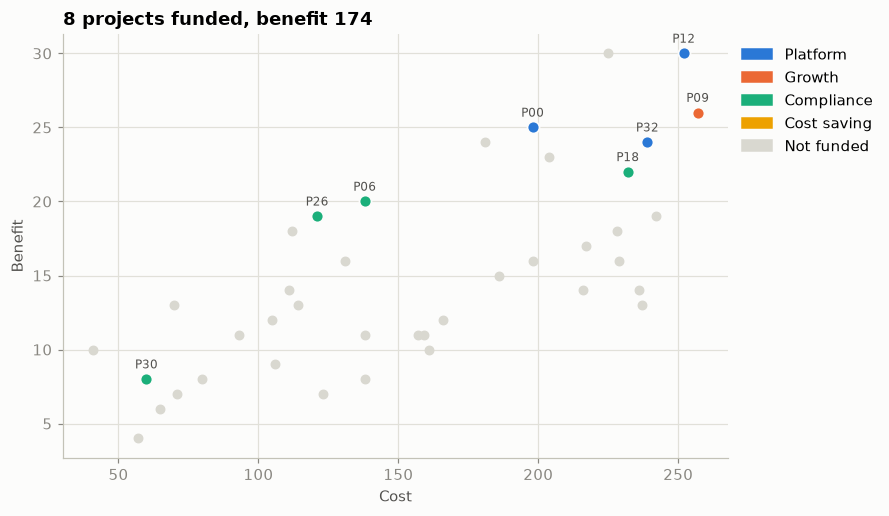

In [4]:
def draw_portfolio(ax, problem, label=True):
    rest = [item for item in problem.items if not item.selected]
    ax.scatter([item.weight for item in rest], [item.value for item in rest], s=30, color="#d9d8d0", zorder=1)
    for item in problem.items:
        if item.selected:
            ax.scatter(item.weight, item.value, s=62, color=THEME_COLOR[theme_of(item.id)],
                       edgecolor="#fcfcfb", linewidth=1.2, zorder=2)
            if label:
                ax.annotate(item.id, (item.weight, item.value), xytext=(0, 7), textcoords="offset points",
                            ha="center", color=INK, fontsize=8)
    ax.set(xlabel="Cost", ylabel="Benefit")
    ax.grid(True)


portfolio_legend = [Patch(color=THEME_COLOR[theme], label=theme) for theme in THEMES]
portfolio_legend.append(Patch(color="#d9d8d0", label="Not funded"))

fig, ax = plt.subplots(figsize=(7.8, 5))
draw_portfolio(ax, problem)
ax.set_title(f"{len(picked)} projects funded, benefit {problem.total_value}")
ax.legend(handles=portfolio_legend, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### What the plan uses

Each bar stacks the funded projects by theme against its limit, so you can see which limit is
tight and where the money and the people went. Budget and engineers have different units, so they
get separate charts.

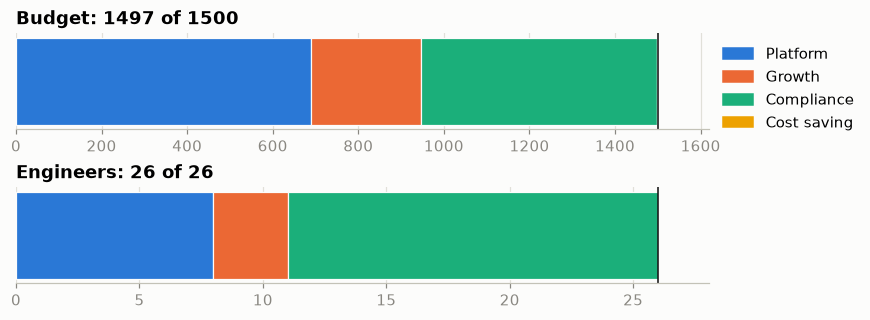

In [5]:
def draw_usage(ax, problem, amount, limit, title):
    left = 0
    for theme in THEMES:
        used = sum(amount(item) for item in problem.items if item.selected and theme_of(item.id) == theme)
        ax.barh(0, used, left=left, height=0.3, color=THEME_COLOR[theme], edgecolor="#fcfcfb", linewidth=0.8)
        left += used
    ax.axvline(limit, color="#0b0b0b", linewidth=1)
    ax.set(title=f"{title}: {left} of {limit}", yticks=[], xlim=(0, limit * 1.08))
    ax.spines["left"].set_visible(False)
    ax.grid(True, axis="x")


fig, axes = plt.subplots(2, 1, figsize=(7.8, 2.8), layout="constrained")
draw_usage(axes[0], problem, lambda item: item.weight, problem.capacity, "Budget")
draw_usage(axes[1], problem, lambda item: item.resource_usage["engineers"], ENGINEERS, "Engineers")
axes[0].legend(handles=portfolio_legend[:4], loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

This recomputes every hard rule from the `selected` flags and the input, with no solver code.

A check of the value is possible too. Drop every rule except the budget, and the problem becomes
the plain knapsack, which dynamic programming solves exactly in a few lines. Fewer rules cannot
give a worse answer, so that number is an upper limit on any plan here. The limit ignores the
engineers and the dependencies, so a real plan may never reach it. It tells you the most that could
be left on the table, not that anything is.

In [6]:
def budget_only_limit(problem):
    """The best total value under the budget alone: an upper limit for the full problem."""
    best = np.zeros(problem.capacity + 1, dtype=np.int64)
    for item in problem.items:
        best[item.weight:] = np.maximum(best[item.weight:], best[:-item.weight] + item.value)
    return int(best[problem.capacity])


chosen = {item.id for item in problem.items if item.selected}
cost = sum(item.weight for item in problem.items if item.selected)
people = sum(item.resource_usage["engineers"] for item in problem.items if item.selected)

print("within budget      :", cost <= problem.capacity, f"({cost})")
print("within engineers   :", people <= ENGINEERS, f"({people})")
print("mandatory funded   :", set(problem.mandatory_items) <= chosen)
print("forbidden left out :", not set(problem.forbidden_items) & chosen)
print("dependencies met   :", all(set(item.requires) <= chosen for item in problem.items if item.selected))
for group in problem.selection_groups:
    print(f"{group.id:19s}:", sorted(chosen & set(group.item_ids)), f"(at most {group.max_selected})")

limit = budget_only_limit(problem)
print(f"benefit {problem.total_value}, upper limit {limit}: the plan reaches "
      f"{100 * problem.total_value / limit:.1f}% of the limit")

within budget      : True (1497)
within engineers   : True (26)
mandatory funded   : True
forbidden left out : True
dependencies met   : True
Billing rewrite    : [] (at most 1)
Data centre move   : [] (at most 1)
Security audit     : ['P06'] (at most 1)
benefit 174, upper limit 209: the plan reaches 83.3% of the limit


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and the
`constraints` argument takes the list you want. Only listed constraints are scored. `weight` scales
a rule, `hard` moves it between levels, and `exponent` shapes large violations.

A headcount limit is rarely absolute: contractors exist, at a price. Flipping
`resource_capacities` to soft with `hard=False` turns it into exactly that. Each engineer over the
limit now costs `weight` points of score instead of being forbidden, so the plan goes over only
where a project is worth more than its contractors.

capacity
resource_capacities
mandatory_items
forbidden_items
selection_group_bounds
item_dependencies
maximize_value


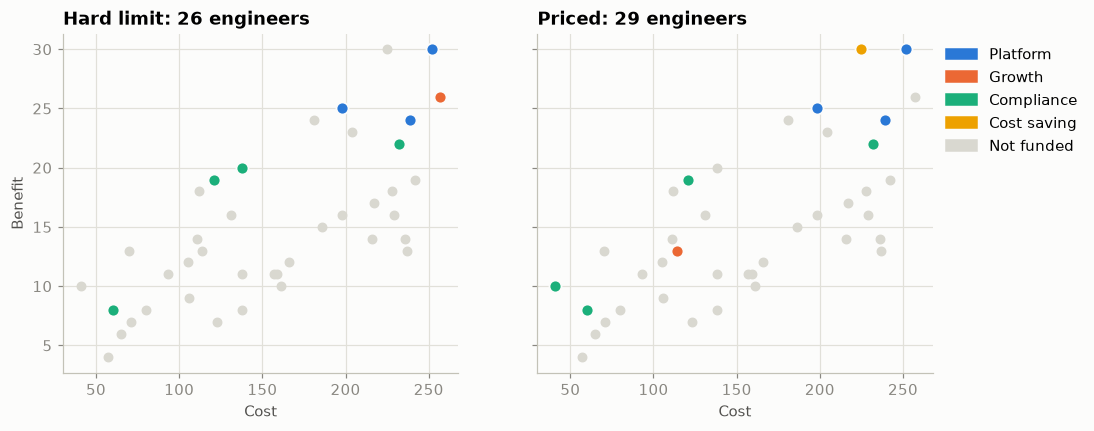

hard limit: benefit 174, budget 1497, 26 engineers
priced    : benefit 181, budget 1482, 29 engineers (3 contractors, score 175)
added  : ['P33', 'P35', 'P38']
dropped: ['P06', 'P09']


In [7]:
for name in ks.list_constraints():
    print(name)

CONTRACTOR_PRICE = 2

contractors = make_problem()
contractor_score = ks.solve(contractors, time_limit_seconds=5, config=search_settings(), constraints=[
    rules.capacity,
    rules.ResourceCapacities(hard=False, weight=CONTRACTOR_PRICE),
    rules.mandatory_items,
    rules.forbidden_items,
    rules.selection_group_bounds,
    rules.item_dependencies,
    rules.maximize_value,
])


def engineers_used(problem):
    return sum(item.resource_usage["engineers"] for item in problem.items if item.selected)


fig, axes = plt.subplots(1, 2, figsize=(10.2, 4), sharex=True, sharey=True)
draw_portfolio(axes[0], problem, label=False)
draw_portfolio(axes[1], contractors, label=False)
axes[0].set_title(f"Hard limit: {engineers_used(problem)} engineers")
axes[1].set_title(f"Priced: {engineers_used(contractors)} engineers")
axes[1].set_ylabel("")
axes[1].legend(handles=portfolio_legend, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

over = max(0, engineers_used(contractors) - ENGINEERS)
print(f"hard limit: benefit {problem.total_value}, budget {problem.total_weight}, "
      f"{engineers_used(problem)} engineers")
print(f"priced    : benefit {contractors.total_value}, budget {contractors.total_weight}, "
      f"{engineers_used(contractors)} engineers ({over} contractors, score {contractor_score[1]:.0f})")

added = sorted({item.id for item in contractors.items if item.selected} - chosen)
dropped = sorted(chosen - {item.id for item in contractors.items if item.selected})
print("added  :", added)
print("dropped:", dropped)

`score_soft` is the benefit minus the contractor charge, while `total_value` is the plain benefit.
Both plans come from a search with a time limit, so a small difference between them can be noise.

## 5. How much is more budget worth?

Here the same proposals are solved for a range of budgets, next to the budget-only upper limit from
section 3.

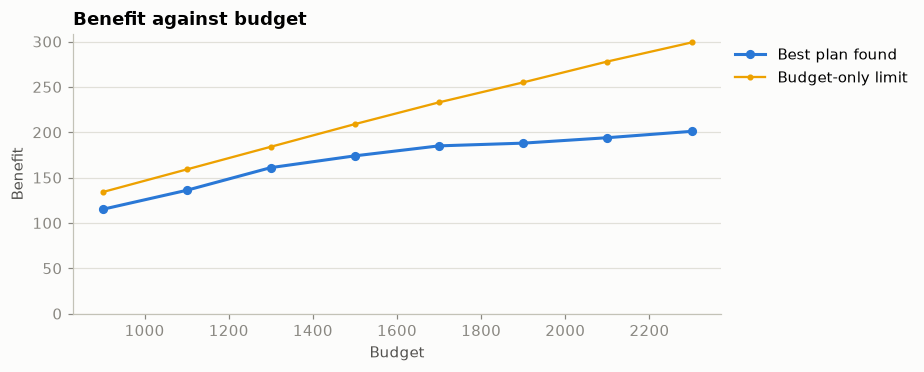

budget 900: benefit 115, engineers 23 of 26, budget-only limit 134
budget 1100: benefit 136, engineers 24 of 26, budget-only limit 159
budget 1300: benefit 161, engineers 26 of 26, budget-only limit 184
budget 1500: benefit 174, engineers 26 of 26, budget-only limit 209
budget 1700: benefit 185, engineers 26 of 26, budget-only limit 233
budget 1900: benefit 188, engineers 25 of 26, budget-only limit 255
budget 2100: benefit 194, engineers 26 of 26, budget-only limit 278
budget 2300: benefit 201, engineers 26 of 26, budget-only limit 299


In [8]:
budgets = list(range(900, 2500, 200))
benefit, ceiling, people_used = [], [], []
for budget in budgets:
    candidate = make_problem(budget)
    candidate_score = ks.solve(candidate, time_limit_seconds=5, config=search_settings())
    assert candidate_score[0] == 0, f"no feasible plan found at budget {budget}"
    benefit.append(candidate.total_value)
    ceiling.append(budget_only_limit(candidate))
    people_used.append(engineers_used(candidate))

fig, ax = plt.subplots(figsize=(7.6, 3.3))
ax.plot(budgets, benefit, color=COLORS[0], linewidth=2, marker="o", markersize=5, label="Best plan found")
ax.plot(budgets, ceiling, color=COLORS[3], linewidth=1.5, marker="o", markersize=3, label="Budget-only limit")
ax.set(title="Benefit against budget", xlabel="Budget", ylabel="Benefit", ylim=(0, None))
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for budget, value, people, top in zip(budgets, benefit, people_used, ceiling):
    print(f"budget {budget}: benefit {value:3d}, engineers {people:2d} of {ENGINEERS}, budget-only limit {top}")

The two lines separate as the budget grows, and the table shows the reason. Once the engineers are
all assigned, more money can only swap projects for better ones. The budget-only limit does not
have that restriction, so it keeps rising. To learn what a further budget would buy, relax the
engineer limit too, as in section 4.

## 6. Match the temperature to your values

Simulated annealing accepts a step that loses `d` points with probability `exp(-d / temperature)`.
The default `temperature` of 2.0 suits differences of a few units. Here a project is worth tens of
points, and dropping one to make room for a better one is the only way to change a full plan,
because each step flips a single project. At the default that first step is almost never taken.
This chart runs the same problem at several temperatures with three seeds each.

temperature 0.5: benefit by seed [128, 147, 125]
temperature 2: benefit by seed [128, 138, 125]
temperature 5: benefit by seed [167, 160, 167]
temperature 20: benefit by seed [168, 174, 174]


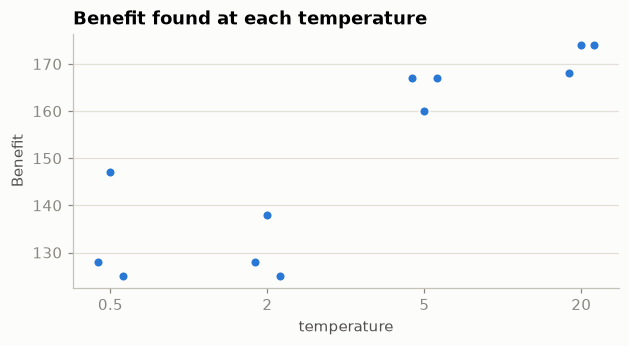

In [9]:
temperatures = [0.5, 2, 5, 20]
fig, ax = plt.subplots(figsize=(6.4, 3))
for position, temperature in enumerate(temperatures):
    results = []
    for seed in range(3):
        candidate = make_problem()
        ks.solve(candidate, time_limit_seconds=5, config=ks.SolverConfig(temperature=temperature, random_seed=seed))
        results.append(candidate.total_value if candidate.score_hard == 0 else np.nan)
    offsets = position + np.array([-0.08, 0, 0.08])  # equal results would hide each other
    ax.scatter(offsets, results, s=42, color=COLORS[0], edgecolor="#fcfcfb", linewidth=1.2)
    print(f"temperature {temperature}: benefit by seed {results}")
ax.set_xticks(range(len(temperatures)), [str(temperature) for temperature in temperatures])
ax.set(title="Benefit found at each temperature", xlabel="temperature", ylabel="Benefit")
ax.grid(True, axis="y")
plt.show()

A seed that ends infeasible is left off the chart and printed as `nan`.

## 7. Restart from last quarter's plan

`with_initial_solution` starts the search from a solved model, or the same thing as a JSON dict,
instead of from the greedy pick. `mandatory_items` and `forbidden_items` are how you pin a project
in or out: both are hard rules.

Suppose the budget is cut by 15% after the plan was made. Projects already under way must continue,
so the first three funded projects become mandatory, and the old plan is now over budget. The
search has to repair it.

**Change `random_seed` between rounds.** A round that finds nothing new leaves the plan as it was,
so with the same seed the next round starts from the same plan with the same random numbers,
repeats the same steps and finds nothing again. The chart runs both ways from the same start, with
a budget of 400 steps per round and four runs each.

same seed 0: [141, 141, 141, 141, 141, 141, 141, 141]
same seed 1: [nan, nan, nan, nan, nan, nan, nan, nan]
same seed 2: [150, 150, 150, 150, 150, 150, 150, 150]
same seed 3: [136, 149, 149, 149, 149, 149, 149, 149]
new seeds from 100: [nan, 144, 150, 150, 150, 150, 150, 150]
new seeds from 200: [144, 144, 150, 150, 150, 150, 150, 150]
new seeds from 300: [144, 150, 150, 150, 150, 150, 150, 150]
new seeds from 400: [142, 145, 145, 145, 145, 145, 145, 149]


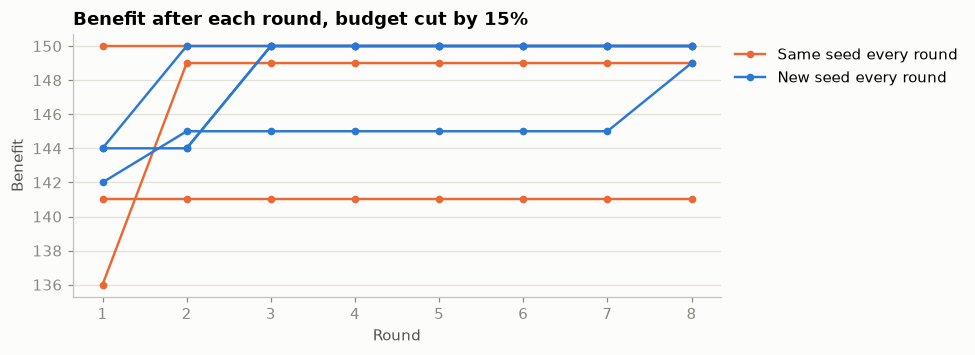

last new-seed plan: score 0 / 149.0, budget 1251 of 1275, 6 of 8 old projects kept
under way still funded: True
a much longer search from scratch: benefit 150, score 0


In [10]:
under_way = [item.id for item in picked[:3]]


def cut_problem():
    cut = make_problem(int(BUDGET * 0.85))
    cut.mandatory_items = [*cut.mandatory_items, *under_way]
    return cut


def run_rounds(seeds, steps=400):
    """Benefit of the best feasible plan after each short round, continuing from the previous one."""
    plan, history = problem, []
    for seed in seeds:
        warm = ks.with_initial_solution(cut_problem(), plan)
        ks.solve(warm, config=ks.SolverConfig(temperature=20, max_iterations=steps, random_seed=seed))
        plan = warm
        history.append(warm.total_value if warm.score_hard == 0 else np.nan)
    return history, plan


ROUNDS = 8
fig, ax = plt.subplots(figsize=(7.6, 3.1))
rounds = range(1, ROUNDS + 1)
for run, seed in enumerate([0, 1, 2, 3]):
    same_seed, _ = run_rounds([seed] * ROUNDS)
    ax.plot(rounds, same_seed, color=COLORS[1], linewidth=1.6, marker="o", markersize=4,
            label="Same seed every round" if run == 0 else None)
    print(f"same seed {seed}:", same_seed)
for run, first_seed in enumerate([100, 200, 300, 400]):
    new_seed, repaired = run_rounds(range(first_seed, first_seed + ROUNDS))
    ax.plot(rounds, new_seed, color=COLORS[0], linewidth=1.6, marker="o", markersize=4,
            label="New seed every round" if run == 0 else None)
    print(f"new seeds from {first_seed}:", new_seed)
ax.set(title="Benefit after each round, budget cut by 15%", xlabel="Round", ylabel="Benefit")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

long_run = cut_problem()
ks.solve(long_run, time_limit_seconds=20, config=ks.SolverConfig(
    temperature=20, random_seed=1, max_iterations=300_000, cooling_rate=0.9999, stagnation_limit=20_000,
))
kept = chosen & {item.id for item in repaired.items if item.selected}
print(f"last new-seed plan: score {repaired.score_hard} / {repaired.score_soft}, budget {repaired.total_weight} "
      f"of {repaired.capacity}, {len(kept)} of {len(chosen)} old projects kept")
print("under way still funded:", set(under_way) <= kept)
print(f"a much longer search from scratch: benefit {long_run.total_value}, score {long_run.score_hard}")

Each line is one run of `ROUNDS` rounds, and a gap means the plan was still infeasible. The orange
lines stop as soon as a round finds nothing, for the reason above. A blue line can also go flat,
and the last printed line is the test for what that means: if a far longer search from scratch
stops at the same benefit, that is evidence, not proof, that the rounds have run
out of improvements to find.


## Next steps

- `use-cases/knapsack/README.md` covers the solver settings and how to add your own moves and costs
  in Python. A swap move, one project out and one in, would remove the valley described in section 6.
- For packing every item into as few containers as possible, see `bin-packing.ipynb`.